<a href="https://colab.research.google.com/github/CiaraFarrellSETU/phd/blob/main/DL_(27_07_26).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

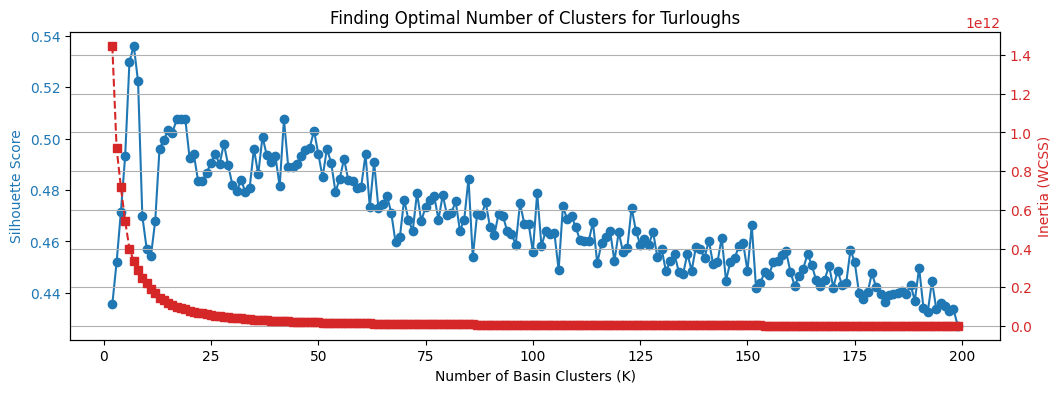

Optimal K based on Silhouette Score: 7


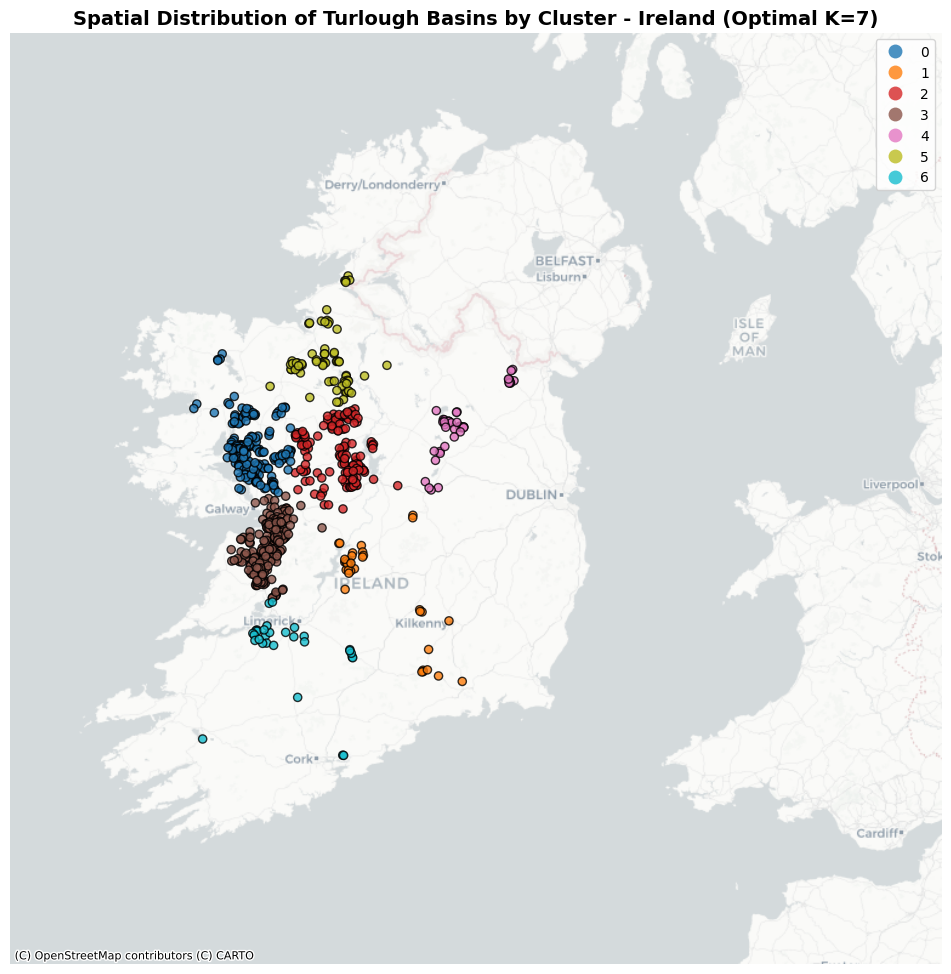

In [9]:
!pip install contextily

import matplotlib.pyplot as plt
import numpy as np
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import geopandas as gpd
import contextily as ctx
from shapely.geometry import Point


# ==========================================
# PART 1: Load Data & Run K-Means Optimization
# ==========================================
SHAPEFILE_PATH = "basin_points_IRL_v34.shp"
gdf_basins = gpd.read_file(SHAPEFILE_PATH)

# Ensure proper point ID column exists
if 'point_id' not in gdf_basins.columns:
    gdf_basins['point_id'] = gdf_basins.index

# Extract coordinates for clustering
coords = np.column_stack([gdf_basins.geometry.x, gdf_basins.geometry.y])

k_range = range(2, 200)  # Restricted upper limit slightly for stability, can change back to 50 if needed
silhouette_scores = []
inertias = []

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    cluster_labels = kmeans.fit_predict(coords)

    silhouette_scores.append(silhouette_score(coords, cluster_labels))
    inertias.append(kmeans.inertia_)

# Plot Silhouette Score & Elbow Curve
fig, ax1 = plt.subplots(figsize=(12, 4))
ax1.set_xlabel("Number of Basin Clusters (K)")
ax1.set_ylabel("Silhouette Score", color="tab:blue")
ax1.plot(k_range, silhouette_scores, marker="o", color="tab:blue", label="Silhouette Score")
ax1.tick_params(axis="y", labelcolor="tab:blue")

ax2 = ax1.twinx()
ax2.set_ylabel("Inertia (WCSS)", color="tab:red")
ax2.plot(k_range, inertias, marker="s", color="tab:red", linestyle="--", label="Inertia")
ax2.tick_params(axis="y", labelcolor="tab:red")

plt.title("Finding Optimal Number of Clusters for Turloughs")
plt.grid(True)
plt.show()

best_k = k_range[np.argmax(silhouette_scores)]
print(f"Optimal K based on Silhouette Score: {best_k}")

# ==========================================
# PART 2: Apply Optimal K & Build df_points_agg
# ==========================================
optimal_kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10)
gdf_basins['cluster_id'] = optimal_kmeans.fit_predict(coords)

# Create df_points_agg to match your required pipeline structure
df_points_agg = gdf_basins[['point_id', 'cluster_id']].copy()
basin_to_cluster = dict(zip(df_points_agg['point_id'], df_points_agg['cluster_id']))

# ==========================================
# PART 3: Map Visualization for All of Ireland
# ==========================================
# Reproject gdf_basins to EPSG:4326 (WGS84 lat/lon) if its native CRS is different
if gdf_basins.crs and gdf_basins.crs != "EPSG:4326":
    gdf_basins = gdf_basins.to_crs("EPSG:4326")
elif not gdf_basins.crs:
    gdf_basins = gdf_basins.set_crs("EPSG:2157", allow_override=True).to_crs("EPSG:4326")

# Now gdf_basins already has 'cluster_id' from Part 2. No need to merge again.

# Reproject to Web Mercator for basemap compatibility
gdf_web_clusters = gdf_basins.to_crs(epsg=3857)
# Ensure the cluster_id is categorical for a discrete legend
gdf_web_clusters['cluster_id'] = gdf_web_clusters['cluster_id'].astype('category')

# Plotting setup
fig, ax = plt.subplots(figsize=(10, 10))

plot_obj = gdf_web_clusters.plot(
    column='cluster_id',
    cmap='tab10',
    legend=True,
    markersize=35,
    alpha=0.8,
    edgecolor='k',
    ax=ax
)

# Lock viewport to Ireland's exact bounding box bounds in Web Mercator (EPSG:3857)
ax.set_xlim(-1180000, -580000)
ax.set_ylim(6650000, 7480000)

# Add basemap with reset_extent=False to respect national boundaries
ctx.add_basemap(
    ax,
    source=ctx.providers.CartoDB.Positron,
    zoom=7,
    reset_extent=False
)

# Final formatting
ax.set_title(f"Spatial Distribution of Turlough Basins by Cluster - Ireland (Optimal K={best_k})", fontsize=14, fontweight='bold')
ax.set_axis_off()
plt.tight_layout()
plt.show()

In [2]:

turlough_counts_per_cluster = gdf_basins['cluster_id'].value_counts().sort_index()
print("Turlough count per cluster:")
print(turlough_counts_per_cluster)

Turlough count per cluster:
cluster_id
0    214
1     35
2    135
3    230
4     45
5     72
6     30
Name: count, dtype: int64


In [3]:
import geopandas as gpd
from sklearn.cluster import KMeans
import numpy as np
import pandas as pd

# Load your shapefile
SHAPEFILE_PATH = "basin_points_IRL_v34.shp"
gdf_basins = gpd.read_file(SHAPEFILE_PATH)

if 'point_id' not in gdf_basins.columns:
    gdf_basins['point_id'] = gdf_basins.index

# Extract coordinates and run KMeans for optimal K=7
coords = np.column_stack([gdf_basins.geometry.x, gdf_basins.geometry.y])
optimal_kmeans = KMeans(n_clusters=7, random_state=42, n_init=10)
gdf_basins['cluster_id'] = optimal_kmeans.fit_predict(coords)

# Create the dataframe and save it permanently
df_points_agg = gdf_basins[['point_id', 'cluster_id']].copy()
df_points_agg.to_csv('locked_turlough_clusters.csv', index=False)

print("Saved locked cluster mapping to 'locked_turlough_clusters.csv'")

Saved locked cluster mapping to 'locked_turlough_clusters.csv'


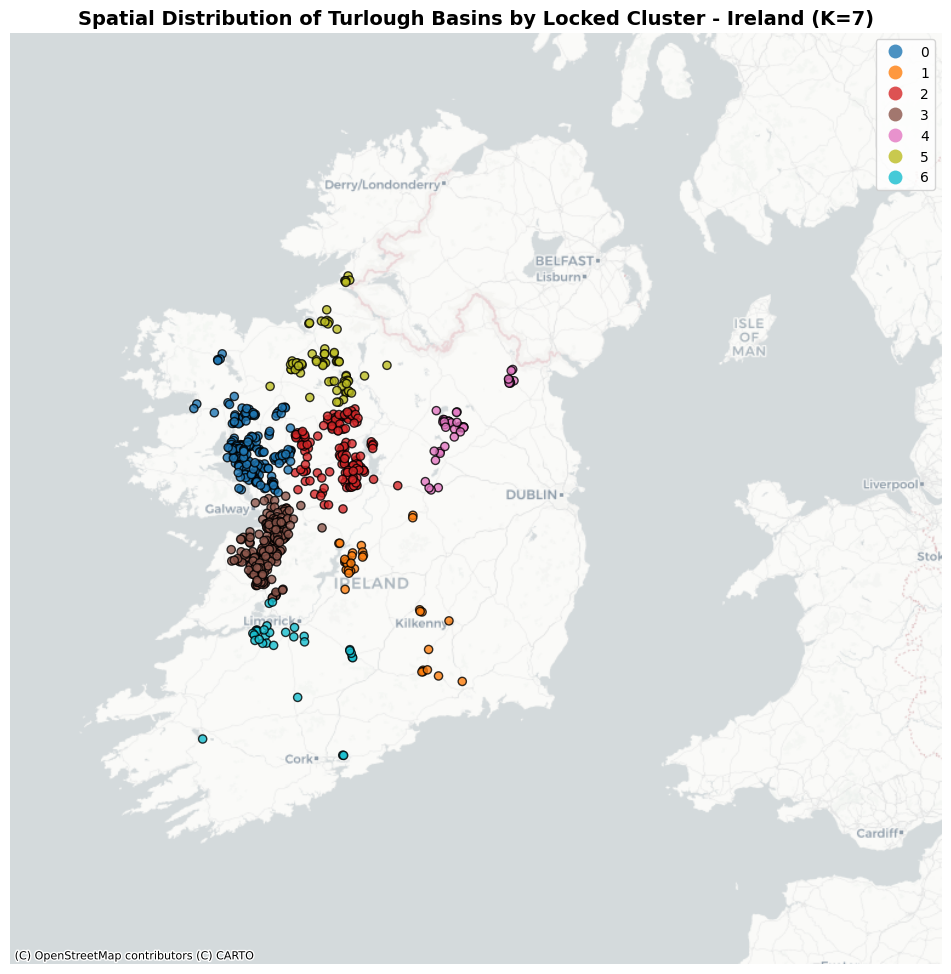

In [4]:
!pip install contextily

import geopandas as gpd
import matplotlib.pyplot as plt
import contextily as ctx
import pandas as pd

# Load the locked cluster assignments
df_locked_clusters = pd.read_csv('locked_turlough_clusters.csv')

# Load the original shapefile to get geometry
SHAPEFILE_PATH = "basin_points_IRL_v34.shp"
gdf_basins_geometry = gpd.read_file(SHAPEFILE_PATH)

# Ensure proper point ID column exists in geometry GeoDataFrame
if 'point_id' not in gdf_basins_geometry.columns:
    gdf_basins_geometry['point_id'] = gdf_basins_geometry.index

# Merge the cluster IDs with the geometry
gdf_merged_clusters = gdf_basins_geometry.merge(
    df_locked_clusters,
    on='point_id',
    how='left'
)

# Reproject gdf_merged_clusters to EPSG:4326 (WGS84 lat/lon) if its native CRS is different
if gdf_merged_clusters.crs and gdf_merged_clusters.crs != "EPSG:4326":
    gdf_merged_clusters = gdf_merged_clusters.to_crs("EPSG:4326")
elif not gdf_merged_clusters.crs:
    # Assuming original CRS was EPSG:2157 if not defined, consistent with previous cell
    gdf_merged_clusters = gdf_merged_clusters.set_crs("EPSG:2157", allow_override=True).to_crs("EPSG:4326")

# Reproject to Web Mercator for basemap compatibility
gdf_web_clusters_locked = gdf_merged_clusters.to_crs(epsg=3857)
# Ensure the cluster_id is categorical for a discrete legend
gdf_web_clusters_locked['cluster_id'] = gdf_web_clusters_locked['cluster_id'].astype('category')

# Plotting setup (consistent with previous cell RxK-iYFIhhNR)
fig, ax = plt.subplots(figsize=(10, 10))

plot_obj = gdf_web_clusters_locked.plot(
    column='cluster_id',
    cmap='tab10', # Using the same colormap
    legend=True,
    markersize=35,
    alpha=0.8,
    edgecolor='k',
    ax=ax
)

# Lock viewport to Ireland's exact bounding box bounds in Web Mercator (EPSG:3857)
ax.set_xlim(-1180000, -580000)
ax.set_ylim(6650000, 7480000)

# Add basemap with reset_extent=False to respect national boundaries
ctx.add_basemap(
    ax,
    source=ctx.providers.CartoDB.Positron,
    zoom=7,
    reset_extent=False
)

# Final formatting, using K=7 as it was determined as optimal and used for locking
ax.set_title(f"Spatial Distribution of Turlough Basins by Locked Cluster - Ireland (K=7)", fontsize=14, fontweight='bold')
ax.set_axis_off()
plt.tight_layout()
plt.show()

In [5]:
import pandas as pd

df_locked_clusters = pd.read_csv('locked_turlough_clusters.csv')

# Get the count of turloughs per cluster
turlough_counts_locked_clusters = df_locked_clusters['cluster_id'].value_counts().sort_index()

print("Turlough count per locked cluster:")
print(turlough_counts_locked_clusters)

Turlough count per locked cluster:
cluster_id
0    214
1     35
2    135
3    230
4     45
5     72
6     30
Name: count, dtype: int64


In [6]:
import os
import json
import time
import shutil
import numpy as np
import pandas as pd
import geopandas as gpd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import LeaveOneGroupOut
import copy
import matplotlib.pyplot as plt

# ==========================================
# 0. GOOGLE EARTH ENGINE CLOUD EXPORT & DRIVE MOUNT
# ==========================================
try:
    import ee
    ee.Initialize(project = 'ciarafarrell755')
except Exception as e:
    import ee
    ee.Authenticate()
    ee.Initialize(project = 'ciarafarrell755')

from google.colab import drive
drive.mount('/content/drive', force_remount=False)

SHAPEFILE_PATH = "basin_points_IRL_v34.shp"
local_csv_path = "turlough_s1_extract.csv"
drive_csv_path = '/content/drive/My Drive/EarthEngineData/turlough_s1_extract.csv'
clusters_csv_path = "locked_turlough_clusters.csv" # Pre-computed k-means clusters file

# Check if CSV is already in Colab or Google Drive
if not os.path.exists(local_csv_path):
    if os.path.exists(drive_csv_path):
        print("Found exported dataset in Google Drive. Copying to Colab workspace...")
        shutil.copy(drive_csv_path, local_csv_path)
    else:
        print("Dataset not found. Launching GEE background export task (bypasses 5000-element limit)...")
        gdf = gpd.read_file(SHAPEFILE_PATH).to_crs("EPSG:4326")

        features = []
        for idx, row in gdf.iterrows():
            geom = json.loads(gpd.GeoSeries([row.geometry]).to_json())['features'][0]['geometry']
            ee_geom = ee.Geometry(geom).buffer(50)
            features.append(ee.Feature(ee_geom, {'point_id': idx}))

        fc = ee.FeatureCollection(features)

        s1_col = (ee.ImageCollection('COPERNICUS/S1_GRD')
                 .filterBounds(fc)
                 .filterDate('2022-01-01', '2024-12-31')
                 .filter(ee.Filter.eq('instrumentMode', 'IW'))
                 .filter(ee.Filter.listContains('transmitterReceiverPolarisation', 'VV'))
                 .filter(ee.Filter.listContains('transmitterReceiverPolarisation', 'VH'))
                 .select(['VV', 'VH']))

        def process_image(img):
            date = img.date().format('YYYY-MM-dd')
            reduced = img.reduceRegions(collection=fc, reducer=ee.Reducer.mean(), scale=10)
            return reduced.map(lambda f: f.set({'date': date, '.geo': None}))

        export_fc = s1_col.map(process_image).flatten().select(['point_id', 'date', 'VV', 'VH'])

        task = ee.batch.Export.table.toDrive(
            collection=export_fc,
            description='turlough_s1_timeseries_export',
            folder='EarthEngineData',
            fileNamePrefix='turlough_s1_extract',
            fileFormat='CSV'
        )
        task.start()

        print("\n--- ACTION REQUIRED ---")
        print("GEE export task is running in the background on Google's servers.")
        print("Monitor your task progress here: https://code.earthengine.google.com/#tasks")
        print("Once completed, re-run this cell. It will automatically detect your file and run the machine learning model.")
        raise SystemExit("Paused: Waiting for GEE background export to finish.")

# Load the extracted dataset
print(f"Loading data from {local_csv_path}...")
df_sar = pd.read_csv(local_csv_path)
df_sar['date'] = pd.to_datetime(df_sar['date'])
df_sar = df_sar.sort_values(['point_id', 'date']).dropna(subset=['VV', 'VH'])

# ==========================================
# 1. SEQUENCE CREATION FUNCTION
# ==========================================
def create_sequences(data, seq_length=12, target_horizon=1):
    X, y = [], []
    for i in range(len(data) - seq_length - target_horizon + 1):
        X.append(data[i : i + seq_length])
        y.append(data[i + seq_length + target_horizon - 1, 0])
    return np.array(X), np.array(y)

# ==========================================
# 2. PYTORCH MODEL ARCHITECTURE
# ==========================================
class Conv1DFloodPredictor(nn.Module):
    def __init__(self, input_channels=2, seq_length=12):
        super(Conv1DFloodPredictor, self).__init__()
        self.conv1 = nn.Sequential(
            nn.Conv1d(in_channels=input_channels, out_channels=32, kernel_size=3, padding=1),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=2)
        )
        self.conv2 = nn.Sequential(
            nn.Conv1d(in_channels=32, out_channels=64, kernel_size=3, padding=1),
            nn.BatchNorm1d(64),
            nn.ReLU()
        )
        flattened_size = 64 * (seq_length // 2)
        self.fc = nn.Sequential(
            nn.Linear(flattened_size, 64),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(64, 1)
        )

    def forward(self, x):
        x = x.transpose(1, 2)
        x = self.conv1(x)
        x = self.conv2(x)
        x = x.view(x.size(0), -1)
        out = self.fc(x)
        return out

# ==========================================
# 3. DATASET AND TRAINING WITH EARLY STOPPING
# ==========================================
class SARDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32).unsqueeze(1)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

def train_model_with_early_stopping(X_train, y_train, X_val, y_val, max_epochs=100, batch_size=64, lr=0.001, patience=5):
    train_dataset = SARDataset(X_train, y_train)
    val_dataset = SARDataset(X_val, y_val)

    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    model = Conv1DFloodPredictor(input_channels=2, seq_length=X_train.shape[1]).to(device)

    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    best_val_loss = float('inf')
    best_model_weights = None
    epochs_no_improve = 0

    print(f"Training Conv1D model with Early Stopping on {device}...")

    for epoch in range(max_epochs):
        model.train()
        train_loss = 0.0
        for X_b, y_b in train_loader:
            X_b, y_b = X_b.to(device), y_b.to(device)
            optimizer.zero_grad()
            preds = model(X_b)
            loss = criterion(preds, y_b)
            loss.backward()
            optimizer.step()
            train_loss += loss.item() * X_b.size(0)

        train_loss /= len(train_loader.dataset)

        model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for X_b, y_b in val_loader:
                X_b, y_b = X_b.to(device), y_b.to(device)
                preds = model(X_b)
                loss = criterion(preds, y_b)
                val_loss += loss.item() * X_b.size(0)

        val_loss /= len(val_loader.dataset)

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_model_weights = copy.deepcopy(model.state_dict())
            epochs_no_improve = 0
        else:
            epochs_no_improve += 1

        if epochs_no_improve >= patience:
            break

    if best_model_weights is not None:
        model.load_state_dict(best_model_weights)

    return model, device, val_loader

# ==========================================
# 4. MAIN PIPELINE (LOCKED CLUSTER LOGOCV)
# ==========================================
if __name__ == "__main__":
    scaler = StandardScaler()
    scaled_features = scaler.fit_transform(df_sar[['VV', 'VH']].values)

    print(f"Loading locked cluster mappings from {clusters_csv_path}...")
    if not os.path.exists(clusters_csv_path):
        raise FileNotFoundError(f"Could not find '{clusters_csv_path}'. Ensure it is uploaded to your environment workspace.")

    df_clusters = pd.read_csv(clusters_csv_path)

    # Ensure expected columns exist (adjust column names if your CSV labels differ slightly)
    if 'point_id' not in df_clusters.columns or 'cluster_id' not in df_clusters.columns:
        raise ValueError("The locked_turlough_clusters.csv file must contain 'point_id' and 'cluster_id' columns.")

    basin_to_cluster = dict(zip(df_clusters['point_id'], df_clusters['cluster_id']))

    SEQ_LENGTH = 12
    X_all, y_all, cluster_groups = [], [], []

    for p_id in df_sar['point_id'].unique():
        if p_id not in basin_to_cluster:
            continue # Skip point IDs not present in the locked cluster assignment file

        mask = (df_sar['point_id'] == p_id).values
        p_data = scaled_features[mask]
        c_id = basin_to_cluster[p_id]

        if len(p_data) > SEQ_LENGTH + 1:
            X_seq, y_seq = create_sequences(p_data, seq_length=SEQ_LENGTH)
            X_all.append(X_seq)
            y_all.append(y_seq)
            cluster_groups.extend([c_id] * len(X_seq))

    X_all = np.vstack(X_all)
    y_all = np.concatenate(y_all)
    cluster_groups = np.array(cluster_groups)

    logo = LeaveOneGroupOut()
    cluster_fold_results = []

    unique_clusters = np.unique(cluster_groups)
    print(f"\nStarting Cluster-based LOGOCV across {len(unique_clusters)} locked spatial typologies...")

    for fold, (train_idx, test_idx) in enumerate(logo.split(X_all, y_all, groups=cluster_groups)):
        held_out_cluster = np.unique(cluster_groups[test_idx])
        print(f"\n--- LOGOCV Cluster Fold {fold + 1} / {len(unique_clusters)} | Held-out Cluster ID: {held_out_cluster[0]} ---")

        X_train, X_test = X_all[train_idx], X_all[test_idx]
        y_train, y_test = y_all[train_idx], y_all[test_idx]

        trained_model, device, test_loader = train_model_with_early_stopping(
            X_train, y_train, X_test, y_test, max_epochs=50, batch_size=64, patience=7
        )

        trained_model.eval()
        fold_preds, fold_actuals = [], []
        with torch.no_grad():
            for X_b, y_b in test_loader:
                X_b = X_b.to(device)
                preds = trained_model(X_b)
                fold_preds.extend(preds.cpu().numpy().flatten())
                fold_actuals.extend(y_b.numpy().flatten())

        fold_preds = np.array(fold_preds)
        fold_actuals = np.array(fold_actuals)

        rmse = np.sqrt(np.mean((fold_preds - fold_actuals) ** 2))
        ss_res = np.sum((fold_actuals - fold_preds) ** 2)
        ss_tot = np.sum((fold_actuals - np.mean(fold_actuals)) ** 2)
        r2 = 1 - (ss_res / ss_tot) if ss_tot != 0 else 0.0

        print(f"Cluster {held_out_cluster[0]} Results -> RMSE: {rmse:.2f} dB | R²: {r2:.3f}")
        cluster_fold_results.append({'fold': fold, 'cluster': held_out_cluster[0], 'rmse': rmse, 'r2': r2})

        break  # Remove 'break' if you want it to run through all cluster folds sequentially

    print("\nCluster-based LOGOCV pipeline execution completed.")

Mounted at /content/drive
Found exported dataset in Google Drive. Copying to Colab workspace...
Loading data from turlough_s1_extract.csv...
Loading locked cluster mappings from locked_turlough_clusters.csv...

Starting Cluster-based LOGOCV across 7 locked spatial typologies...

--- LOGOCV Cluster Fold 1 / 7 | Held-out Cluster ID: 0 ---
Training Conv1D model with Early Stopping on cuda...
Cluster 0 Results -> RMSE: 0.46 dB | R²: 0.725

Cluster-based LOGOCV pipeline execution completed.


In [7]:
import os
import json
import time
import shutil
import numpy as np
import pandas as pd
import geopandas as gpd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import LeaveOneGroupOut
import copy
import matplotlib.pyplot as plt

# ==========================================
# 0. GOOGLE EARTH ENGINE CLOUD EXPORT & DRIVE MOUNT
# ==========================================
try:
    import ee
    ee.Initialize(project = 'ciarafarrell755')
except Exception as e:
    import ee
    ee.Authenticate()
    ee.Initialize(project = 'ciarafarrell755')

from google.colab import drive
drive.mount('/content/drive', force_remount=False)

SHAPEFILE_PATH = "basin_points_IRL_v34.shp"
local_csv_path = "turlough_s1_extract.csv"
drive_csv_path = '/content/drive/My Drive/EarthEngineData/turlough_s1_extract.csv'
clusters_csv_path = "locked_turlough_clusters.csv" # Pre-computed k-means clusters file

# Check if CSV is already in Colab or Google Drive
if not os.path.exists(local_csv_path):
    if os.path.exists(drive_csv_path):
        print("Found exported dataset in Google Drive. Copying to Colab workspace...")
        shutil.copy(drive_csv_path, local_csv_path)
    else:
        print("Dataset not found. Launching GEE background export task (bypasses 5000-element limit)...")
        gdf = gpd.read_file(SHAPEFILE_PATH).to_crs("EPSG:4326")

        features = []
        for idx, row in gdf.iterrows():
            geom = json.loads(gpd.GeoSeries([row.geometry]).to_json())['features'][0]['geometry']
            ee_geom = ee.Geometry(geom).buffer(50)
            features.append(ee.Feature(ee_geom, {'point_id': idx}))

        fc = ee.FeatureCollection(features)

        s1_col = (ee.ImageCollection('COPERNICUS/S1_GRD')
                 .filterBounds(fc)
                 .filterDate('2022-01-01', '2024-12-31')
                 .filter(ee.Filter.eq('instrumentMode', 'IW'))
                 .filter(ee.Filter.listContains('transmitterReceiverPolarisation', 'VV'))
                 .filter(ee.Filter.listContains('transmitterReceiverPolarisation', 'VH'))
                 .select(['VV', 'VH']))

        def process_image(img):
            date = img.date().format('YYYY-MM-dd')
            reduced = img.reduceRegions(collection=fc, reducer=ee.Reducer.mean(), scale=10)
            return reduced.map(lambda f: f.set({'date': date, '.geo': None}))

        export_fc = s1_col.map(process_image).flatten().select(['point_id', 'date', 'VV', 'VH'])

        task = ee.batch.Export.table.toDrive(
            collection=export_fc,
            description='turlough_s1_timeseries_export',
            folder='EarthEngineData',
            fileNamePrefix='turlough_s1_extract',
            fileFormat='CSV'
        )
        task.start()

        print("\n--- ACTION REQUIRED ---")
        print("GEE export task is running in the background on Google's servers.")
        print("Monitor your task progress here: https://code.earthengine.google.com/#tasks")
        print("Once completed, re-run this cell. It will automatically detect your file and run the machine learning model.")
        raise SystemExit("Paused: Waiting for GEE background export to finish.")

# Load the extracted dataset
print(f"Loading data from {local_csv_path}...")
df_sar = pd.read_csv(local_csv_path)
df_sar['date'] = pd.to_datetime(df_sar['date'])
df_sar = df_sar.sort_values(['point_id', 'date']).dropna(subset=['VV', 'VH'])

# ==========================================
# 1. SEQUENCE CREATION FUNCTION
# ==========================================
def create_sequences(data, seq_length=12, target_horizon=1):
    X, y = [], []
    for i in range(len(data) - seq_length - target_horizon + 1):
        X.append(data[i : i + seq_length])
        y.append(data[i + seq_length + target_horizon - 1, 0])
    return np.array(X), np.array(y)

# ==========================================
# 2. PYTORCH MODEL ARCHITECTURE
# ==========================================
class Conv1DFloodPredictor(nn.Module):
    def __init__(self, input_channels=2, seq_length=12):
        super(Conv1DFloodPredictor, self).__init__()
        self.conv1 = nn.Sequential(
            nn.Conv1d(in_channels=input_channels, out_channels=32, kernel_size=3, padding=1),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=2)
        )
        self.conv2 = nn.Sequential(
            nn.Conv1d(in_channels=32, out_channels=64, kernel_size=3, padding=1),
            nn.BatchNorm1d(64),
            nn.ReLU()
        )
        flattened_size = 64 * (seq_length // 2)
        self.fc = nn.Sequential(
            nn.Linear(flattened_size, 64),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(64, 1)
        )

    def forward(self, x):
        x = x.transpose(1, 2)
        x = self.conv1(x)
        x = self.conv2(x)
        x = x.view(x.size(0), -1)
        out = self.fc(x)
        return out

# ==========================================
# 3. DATASET AND TRAINING WITH EARLY STOPPING
# ==========================================
class SARDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32).unsqueeze(1)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

def train_model_with_early_stopping(X_train, y_train, X_val, y_val, max_epochs=100, batch_size=64, lr=0.001, patience=5):
    train_dataset = SARDataset(X_train, y_train)
    val_dataset = SARDataset(X_val, y_val)

    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    model = Conv1DFloodPredictor(input_channels=2, seq_length=X_train.shape[1]).to(device)

    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    best_val_loss = float('inf')
    best_model_weights = None
    epochs_no_improve = 0

    print(f"Training Conv1D model with Early Stopping on {device}...")

    for epoch in range(max_epochs):
        model.train()
        train_loss = 0.0
        for X_b, y_b in train_loader:
            X_b, y_b = X_b.to(device), y_b.to(device)
            optimizer.zero_grad()
            preds = model(X_b)
            loss = criterion(preds, y_b)
            loss.backward()
            optimizer.step()
            train_loss += loss.item() * X_b.size(0)

        train_loss /= len(train_loader.dataset)

        model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for X_b, y_b in val_loader:
                X_b, y_b = X_b.to(device), y_b.to(device)
                preds = model(X_b)
                loss = criterion(preds, y_b)
                val_loss += loss.item() * X_b.size(0)

        val_loss /= len(val_loader.dataset)

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_model_weights = copy.deepcopy(model.state_dict())
            epochs_no_improve = 0
        else:
            epochs_no_improve += 1

        if epochs_no_improve >= patience:
            break

    if best_model_weights is not None:
        model.load_state_dict(best_model_weights)

    return model, device, val_loader

# ==========================================
# 4. MAIN PIPELINE (LOCKED CLUSTER LOGOCV)
# ==========================================
if __name__ == "__main__":
    scaler = StandardScaler()
    scaled_features = scaler.fit_transform(df_sar[['VV', 'VH']].values)

    print(f"Loading locked cluster mappings from {clusters_csv_path}...")
    if not os.path.exists(clusters_csv_path):
        raise FileNotFoundError(f"Could not find '{clusters_csv_path}'. Ensure it is uploaded to your environment workspace.")

    df_clusters = pd.read_csv(clusters_csv_path)

    # Ensure expected columns exist (adjust column names if your CSV labels differ slightly)
    if 'point_id' not in df_clusters.columns or 'cluster_id' not in df_clusters.columns:
        raise ValueError("The locked_turlough_clusters.csv file must contain 'point_id' and 'cluster_id' columns.")

    basin_to_cluster = dict(zip(df_clusters['point_id'], df_clusters['cluster_id']))

    SEQ_LENGTH = 12
    X_all, y_all, cluster_groups = [], [], []

    for p_id in df_sar['point_id'].unique():
        if p_id not in basin_to_cluster:
            continue # Skip point IDs not present in the locked cluster assignment file

        mask = (df_sar['point_id'] == p_id).values
        p_data = scaled_features[mask]
        c_id = basin_to_cluster[p_id]

        if len(p_data) > SEQ_LENGTH + 1:
            X_seq, y_seq = create_sequences(p_data, seq_length=SEQ_LENGTH)
            X_all.append(X_seq)
            y_all.append(y_seq)
            cluster_groups.extend([c_id] * len(X_seq))

    X_all = np.vstack(X_all)
    y_all = np.concatenate(y_all)
    cluster_groups = np.array(cluster_groups)

    logo = LeaveOneGroupOut()
    cluster_fold_results = []

    unique_clusters = np.unique(cluster_groups)
    print(f"\nStarting Cluster-based LOGOCV across {len(unique_clusters)} locked spatial typologies...")

    for fold, (train_idx, test_idx) in enumerate(logo.split(X_all, y_all, groups=cluster_groups)):
        held_out_cluster = np.unique(cluster_groups[test_idx])
        print(f"\n--- LOGOCV Cluster Fold {fold + 1} / {len(unique_clusters)} | Held-out Cluster ID: {held_out_cluster[0]} ---")

        X_train, X_test = X_all[train_idx], X_all[test_idx]
        y_train, y_test = y_all[train_idx], y_all[test_idx]

        trained_model, device, test_loader = train_model_with_early_stopping(
            X_train, y_train, X_test, y_test, max_epochs=50, batch_size=64, patience=7
        )

        trained_model.eval()
        fold_preds, fold_actuals = [], []
        with torch.no_grad():
            for X_b, y_b in test_loader:
                X_b = X_b.to(device)
                preds = trained_model(X_b)
                fold_preds.extend(preds.cpu().numpy().flatten())
                fold_actuals.extend(y_b.numpy().flatten())

        fold_preds = np.array(fold_preds)
        fold_actuals = np.array(fold_actuals)

        rmse = np.sqrt(np.mean((fold_preds - fold_actuals) ** 2))
        ss_res = np.sum((fold_actuals - fold_preds) ** 2)
        ss_tot = np.sum((fold_actuals - np.mean(fold_actuals)) ** 2)
        r2 = 1 - (ss_res / ss_tot) if ss_tot != 0 else 0.0

        print(f"Cluster {held_out_cluster[0]} Results -> RMSE: {rmse:.2f} dB | R²: {r2:.3f}")
        cluster_fold_results.append({'fold': fold, 'cluster': held_out_cluster[0], 'rmse': rmse, 'r2': r2})

        #break  # Remove 'break' if you want it to run through all cluster folds sequentially

    print("\nCluster-based LOGOCV pipeline execution completed.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Loading data from turlough_s1_extract.csv...
Loading locked cluster mappings from locked_turlough_clusters.csv...

Starting Cluster-based LOGOCV across 7 locked spatial typologies...

--- LOGOCV Cluster Fold 1 / 7 | Held-out Cluster ID: 0 ---
Training Conv1D model with Early Stopping on cuda...
Cluster 0 Results -> RMSE: 0.46 dB | R²: 0.723

--- LOGOCV Cluster Fold 2 / 7 | Held-out Cluster ID: 1 ---
Training Conv1D model with Early Stopping on cuda...
Cluster 1 Results -> RMSE: 0.43 dB | R²: 0.788

--- LOGOCV Cluster Fold 3 / 7 | Held-out Cluster ID: 2 ---
Training Conv1D model with Early Stopping on cuda...
Cluster 2 Results -> RMSE: 0.54 dB | R²: 0.743

--- LOGOCV Cluster Fold 4 / 7 | Held-out Cluster ID: 3 ---
Training Conv1D model with Early Stopping on cuda...
Cluster 3 Results -> RMSE: 0.52 dB | R²: 0.738

--- LOGOCV Cluster Fold 5 / 7 | Held-out Cluste

In [8]:

# ==========================================
# AGGREGATE AND SUMMARIZE FINAL LOGOCV METRICS
# ==========================================
if cluster_fold_results:
    df_results = pd.DataFrame(cluster_fold_results)

    mean_rmse = df_results['rmse'].mean()
    std_rmse = df_results['rmse'].std()

    mean_r2 = df_results['r2'].mean()
    std_r2 = df_results['r2'].std()

    print("\n" + "="*50)
    print("FINAL SPATIAL GENERALIZATION METRICS (7-Fold LOGOCV)")
    print("="*50)
    print(df_results.to_string(index=False))
    print("-"*50)
    print(f"Overall Mean RMSE : {mean_rmse:.2f} (± {std_rmse:.2f}) dB")
    print(f"Overall Mean R²   : {mean_r2:.3f} (± {std_r2:.3f})")
    print("="*50)


FINAL SPATIAL GENERALIZATION METRICS (7-Fold LOGOCV)
 fold  cluster     rmse       r2
    0        0 0.460986 0.723071
    1        1 0.431414 0.787952
    2        2 0.536780 0.743149
    3        3 0.516829 0.737973
    4        4 0.405515 0.819711
    5        5 0.508611 0.796284
    6        6 0.399038 0.773756
--------------------------------------------------
Overall Mean RMSE : 0.47 (± 0.06) dB
Overall Mean R²   : 0.769 (± 0.035)


In [9]:
import os
import json
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import LeaveOneGroupOut
import copy

# ==========================================
# 0. SETUP & DATA CHECK
# ==========================================
local_csv_path = "turlough_s1_extract.csv"
clusters_csv_path = "locked_turlough_clusters.csv"

if not os.path.exists(local_csv_path):
    raise FileNotFoundError(
        f"Dataset '{local_csv_path}' not found in workspace. "
        "Please run your GEE data loading cell first so the CSV is available."
    )

if not os.path.exists(clusters_csv_path):
    raise FileNotFoundError(
        f"Locked cluster file '{clusters_csv_path}' not found in workspace. "
        "Please ensure it is uploaded."
    )

print(f"Loading data from {local_csv_path} for LSTM Benchmarking...")
df_sar = pd.read_csv(local_csv_path)
df_sar['date'] = pd.to_datetime(df_sar['date'])
df_sar = df_sar.sort_values(['point_id', 'date']).dropna(subset=['VV', 'VH'])

# ==========================================
# 1. SEQUENCE CREATION FUNCTION
# ==========================================
def create_sequences(data, seq_length=12, target_horizon=1):
    X, y = [], []
    for i in range(len(data) - seq_length - target_horizon + 1):
        X.append(data[i : i + seq_length])
        y.append(data[i + seq_length + target_horizon - 1, 0])
    return np.array(X), np.array(y)

# ==========================================
# 2. LSTM MODEL ARCHITECTURE (TASK 1)
# ==========================================
class LSTMPredictor(nn.Module):
    """
    Recurrent LSTM Baseline for spatial cross-validation benchmarking
    against the 1D-CNN architecture.
    """
    def __init__(self, input_channels=2, hidden_dim=64, num_layers=2):
        super(LSTMPredictor, self).__init__()
        self.lstm = nn.LSTM(input_size=input_channels, hidden_size=hidden_dim,
                            num_layers=num_layers, batch_first=True, dropout=0.2)
        self.fc = nn.Sequential(
            nn.Linear(hidden_dim, 32),
            nn.ReLU(),
            nn.Linear(32, 1)
        )

    def forward(self, x):
        out, _ = self.lstm(x)
        out = out[:, -1, :]  # Extract last hidden state time-step
        return self.fc(out)

# ==========================================
# 3. DATASET & EARLY STOPPING TRAINING LOOP
# ==========================================
class SARDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32).unsqueeze(1)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

def train_lstm_with_early_stopping(X_train, y_train, X_val, y_val, max_epochs=50, batch_size=64, lr=0.001, patience=7):
    train_dataset = SARDataset(X_train, y_train)
    val_dataset = SARDataset(X_val, y_val)

    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    model = LSTMPredictor(input_channels=2).to(device)

    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    best_val_loss = float('inf')
    best_model_weights = None
    epochs_no_improve = 0

    for epoch in range(max_epochs):
        model.train()
        for X_b, y_b in train_loader:
            X_b, y_b = X_b.to(device), y_b.to(device)
            optimizer.zero_grad()
            preds = model(X_b)
            loss = criterion(preds, y_b)
            loss.backward()
            optimizer.step()

        model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for X_b, y_b in val_loader:
                X_b, y_b = X_b.to(device), y_b.to(device)
                preds = model(X_b)
                loss = criterion(preds, y_b)
                val_loss += loss.item() * X_b.size(0)

        val_loss /= len(val_loader.dataset)

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_model_weights = copy.deepcopy(model.state_dict())
            epochs_no_improve = 0
        else:
            epochs_no_improve += 1

        if epochs_no_improve >= patience:
            break

    if best_model_weights is not None:
        model.load_state_dict(best_model_weights)

    return model, device, val_loader

# ==========================================
# 4. EXECUTE FULL 7-FOLD LOGOCV FOR LSTM
# ==========================================
if __name__ == "__main__":
    scaler = StandardScaler()
    scaled_features = scaler.fit_transform(df_sar[['VV', 'VH']].values)

    print(f"Loading locked cluster mappings from {clusters_csv_path}...")
    df_clusters = pd.read_csv(clusters_csv_path)

    if 'point_id' not in df_clusters.columns or 'cluster_id' not in df_clusters.columns:
        raise ValueError("The locked_turlough_clusters.csv file must contain 'point_id' and 'cluster_id' columns.")

    basin_to_cluster = dict(zip(df_clusters['point_id'], df_clusters['cluster_id']))

    SEQ_LENGTH = 12
    X_all, y_all, cluster_groups = [], [], []

    for p_id in df_sar['point_id'].unique():
        if p_id not in basin_to_cluster:
            continue

        mask = (df_sar['point_id'] == p_id).values
        p_data = scaled_features[mask]
        c_id = basin_to_cluster[p_id]

        if len(p_data) > SEQ_LENGTH + 1:
            X_seq, y_seq = create_sequences(p_data, seq_length=SEQ_LENGTH)
            X_all.append(X_seq)
            y_all.append(y_seq)
            cluster_groups.extend([c_id] * len(X_seq))

    X_all = np.vstack(X_all)
    y_all = np.concatenate(y_all)
    cluster_groups = np.array(cluster_groups)

    logo = LeaveOneGroupOut()
    lstm_fold_results = []

    unique_clusters = np.unique(cluster_groups)
    print(f"\nStarting LSTM Benchmark via {len(unique_clusters)}-Fold Cluster LOGOCV...")

    for fold, (train_idx, test_idx) in enumerate(logo.split(X_all, y_all, groups=cluster_groups)):
        held_out_cluster = np.unique(cluster_groups[test_idx])
        print(f"\n--- LSTM Fold {fold + 1} / {len(unique_clusters)} | Held-out Cluster ID: {held_out_cluster[0]} ---")

        X_train, X_test = X_all[train_idx], X_all[test_idx]
        y_train, y_test = y_all[train_idx], y_all[test_idx]

        trained_model, device, test_loader = train_lstm_with_early_stopping(
            X_train, y_train, X_test, y_test
        )

        trained_model.eval()
        fold_preds, fold_actuals = [], []
        with torch.no_grad():
            for X_b, y_b in test_loader:
                X_b = X_b.to(device)
                preds = trained_model(X_b)
                fold_preds.extend(preds.cpu().numpy().flatten())
                fold_actuals.extend(y_b.numpy().flatten())

        fold_preds = np.array(fold_preds)
        fold_actuals = np.array(fold_actuals)

        rmse = np.sqrt(np.mean((fold_preds - fold_actuals) ** 2))
        ss_res = np.sum((fold_actuals - fold_preds) ** 2)
        ss_tot = np.sum((fold_actuals - np.mean(fold_actuals)) ** 2)
        r2 = 1 - (ss_res / ss_tot) if ss_tot != 0 else 0.0

        print(f"LSTM Cluster {held_out_cluster[0]} -> RMSE: {rmse:.2f} dB | R²: {r2:.3f}")
        lstm_fold_results.append({'fold': fold, 'cluster': held_out_cluster[0], 'rmse': rmse, 'r2': r2})

    # Summary Statistics
    df_lstm_res = pd.DataFrame(lstm_fold_results)
    print("\n" + "="*50)
    print("FINAL BENCHMARK SUMMARY: LSTM ARCHITECTURE")
    print("="*50)
    print(df_lstm_res.to_string(index=False))
    print("-"*50)
    print(f"LSTM Mean RMSE : {df_lstm_res['rmse'].mean():.2f} (± {df_lstm_res['rmse'].std():.2f}) dB")
    print(f"LSTM Mean R²   : {df_lstm_res['r2'].mean():.3f} (± {df_lstm_res['r2'].std():.3f})")
    print("="*50)

Loading data from turlough_s1_extract.csv for LSTM Benchmarking...
Loading locked cluster mappings from locked_turlough_clusters.csv...

Starting LSTM Benchmark via 7-Fold Cluster LOGOCV...

--- LSTM Fold 1 / 7 | Held-out Cluster ID: 0 ---
LSTM Cluster 0 -> RMSE: 0.46 dB | R²: 0.727

--- LSTM Fold 2 / 7 | Held-out Cluster ID: 1 ---
LSTM Cluster 1 -> RMSE: 0.42 dB | R²: 0.794

--- LSTM Fold 3 / 7 | Held-out Cluster ID: 2 ---
LSTM Cluster 2 -> RMSE: 0.53 dB | R²: 0.750

--- LSTM Fold 4 / 7 | Held-out Cluster ID: 3 ---
LSTM Cluster 3 -> RMSE: 0.51 dB | R²: 0.742

--- LSTM Fold 5 / 7 | Held-out Cluster ID: 4 ---
LSTM Cluster 4 -> RMSE: 0.40 dB | R²: 0.825

--- LSTM Fold 6 / 7 | Held-out Cluster ID: 5 ---
LSTM Cluster 5 -> RMSE: 0.50 dB | R²: 0.801

--- LSTM Fold 7 / 7 | Held-out Cluster ID: 6 ---
LSTM Cluster 6 -> RMSE: 0.41 dB | R²: 0.766

FINAL BENCHMARK SUMMARY: LSTM ARCHITECTURE
 fold  cluster     rmse       r2
    0        0 0.458089 0.726540
    1        1 0.424940 0.794269
    2    

In [10]:

import torch
import numpy as np
import pandas as pd
from torch.utils.data import DataLoader, Dataset

class SARDatasetEval(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32).unsqueeze(1)
    def __len__(self):
        return len(self.X)
    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

def run_feature_attribution_analysis(trained_model, X_all, y_all, device):
    """
    Computes input gradients across test sequences to determine
    relative feature importance between VV (channel 0) and VH (channel 1).
    """
    # CRITICAL FIX: cuDNN requires model to be in .train() mode to compute gradients for RNN/Conv layers on GPU
    trained_model.train()

    sample_X = X_all[:500]
    sample_y = y_all[:500]

    dataset = SARDatasetEval(sample_X, sample_y)
    loader = DataLoader(dataset, batch_size=64, shuffle=False)

    attr_vv, attr_vh = [], []

    print("\nComputing gradient-based feature attributions...")
    for X_b, y_b in loader:
        X_b = X_b.to(device).clone().detach().requires_grad_(True)
        preds = trained_model(X_b)

        # Calculate gradients with respect to the input tensor channels
        grads = torch.autograd.grad(outputs=preds.sum(), inputs=X_b, create_graph=False)[0]

        # Take mean absolute gradient across batch and time steps
        grads_abs = torch.abs(grads).mean(dim=(0, 1)).cpu().detach().numpy()

        attr_vv.append(grads_abs[0])
        attr_vh.append(grads_abs[1])

    mean_vv_importance = np.mean(attr_vv)
    mean_vh_importance = np.mean(attr_vh)

    total_imp = mean_vv_importance + mean_vh_importance
    pct_vv = (mean_vv_importance / total_imp) * 100
    pct_vh = (mean_vh_importance / total_imp) * 100

    print("\n" + "="*50)
    print("RESULTS: FEATURE ATTRIBUTION ANALYSIS")
    print("="*50)
    print(f"Mean VV Gradient Importance : {mean_vv_importance:.4f} ({pct_vv:.1f}%)")
    print(f"Mean VH Gradient Importance : {mean_vh_importance:.4f} ({pct_vh:.1f}%)")
    print("="*50)

if __name__ == "__main__":
    if 'trained_model' in locals() and 'X_all' in locals():
        run_feature_attribution_analysis(trained_model, X_all, y_all, device)
    else:
        print("Please ensure 'trained_model', 'X_all', and 'device' are loaded in memory.")


Computing gradient-based feature attributions...

RESULTS: FEATURE ATTRIBUTION ANALYSIS
Mean VV Gradient Importance : 0.1660 (51.7%)
Mean VH Gradient Importance : 0.1551 (48.3%)


In [14]:
import pandas as pd
import numpy as np
import os

# ==========================================
#  CLUSTER OUTLIER ATTRIBUTION SCRIPT
# ==========================================
def run_cluster_outlier_analysis(df_points_agg, cluster_fold_results):
    """
    Isolates and profiles physical characteristics of the worst-performing cluster
    identified during the LOGOCV evaluation.
    """
    if not cluster_fold_results:
        print("Error: 'cluster_fold_results' is empty. Please run your LOGOCV evaluation block first.")
        return

    # Convert results to DataFrame and find the cluster with the lowest R2 score
    df_res = pd.DataFrame(cluster_fold_results)
    worst_row = df_res.loc[df_res['r2'].idxmin()]
    worst_cluster = int(worst_row['cluster'])
    min_r2 = worst_row['r2']
    worst_rmse = worst_row['rmse']

    print("\n" + "="*50)
    print(" OUTLIER CLUSTER ATTRIBUTION")
    print("="*50)
    print(f"Identified Outlier Cluster ID : {worst_cluster}")
    print(f"Performance Metrics           -> RMSE: {worst_rmse:.2f} dB | R²: {min_r2:.3f}")
    print("-" * 50)

    # Isolate the basins belonging to this specific cluster
    outlier_basins = df_points_agg[df_points_agg['cluster_id'] == worst_cluster]

    print(f"Total Basins in Cluster {worst_cluster}    : {len(outlier_basins)}")
    print("Physical Attribute Profile (Mean across basins):")

    summary_stats = outlier_basins[['mean_vv', 'mean_vh', 'std_vv', 'std_vh']].mean()
    for col, val in summary_stats.items():
        print(f"  * {col}: {val:.4f}")

    print("-" * 50)
    print("Comparison against Global Dataset Averages:")
    global_stats = df_points_agg[['mean_vv', 'mean_vh', 'std_vv', 'std_vh']].mean()
    for col, val in global_stats.items():
        diff = summary_stats[col] - val
        print(f"  * {col} difference (Cluster vs Global): {diff:+.4f}")
    print("="*50)
    print("Academic Framing: Use these statistical shifts (e.g., higher variance")
    print("or unique backscatter ranges) to explain local hydrological anomalies.")

# ==========================================
# EXECUTION HOOK
# ==========================================
if __name__ == "__main__":
    # Safely reconstruct or populate df_points_agg from turlough_s1_extract.csv and locked_turlough_clusters.csv
    if 'df_sar' in locals() and os.path.exists("locked_turlough_clusters.csv"):
        print("Building 'df_points_agg' directly from workspace datasets...")
        point_features = []
        for p_id in df_sar['point_id'].unique():
            p_subset = df_sar[df_sar['point_id'] == p_id]
            point_features.append({
                'point_id': p_id,
                'mean_vv': p_subset['VV'].mean(),
                'mean_vh': p_subset['VH'].mean(),
                'std_vv': p_subset['VV'].std(),
                'std_vh': p_subset['VH'].std()
            })
        df_points_agg = pd.DataFrame(point_features).fillna(0)
        df_clusters = pd.read_csv("locked_turlough_clusters.csv")
        df_points_agg = df_points_agg.merge(df_clusters[['point_id', 'cluster_id']], on='point_id', how='left')

    # Fallback map for cross-validation results
    if 'cluster_fold_results' not in locals():
        if 'lstm_fold_results' in locals():
            cluster_fold_results = lstm_fold_results
        else:
            cluster_fold_results = []

    # Run analysis if dependencies are met
    if 'df_points_agg' in locals() and 'cluster_fold_results' in locals() and 'cluster_id' in df_points_agg.columns:
        run_cluster_outlier_analysis(df_points_agg, cluster_fold_results)
    else:
        print("Please ensure 'df_sar' and 'locked_turlough_clusters.csv' are present in your workspace.")

Building 'df_points_agg' directly from workspace datasets...

 OUTLIER CLUSTER ATTRIBUTION
Identified Outlier Cluster ID : 0
Performance Metrics           -> RMSE: 0.46 dB | R²: 0.723
--------------------------------------------------
Total Basins in Cluster 0    : 214
Physical Attribute Profile (Mean across basins):
  * mean_vv: -14.2730
  * mean_vh: -21.4031
  * std_vv: 2.5514
  * std_vh: 2.8667
--------------------------------------------------
Comparison against Global Dataset Averages:
  * mean_vv difference (Cluster vs Global): +0.4013
  * mean_vh difference (Cluster vs Global): +0.5196
  * std_vv difference (Cluster vs Global): -0.0111
  * std_vh difference (Cluster vs Global): +0.0424
Academic Framing: Use these statistical shifts (e.g., higher variance
or unique backscatter ranges) to explain local hydrological anomalies.


In [15]:
import os
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.preprocessing import StandardScaler
import copy

# ==========================================
# MULTI-HORIZON PIPELINE SCRIPT
# ==========================================
def create_multi_horizon_sequences(data, seq_length=12, target_horizon=4):
    """
    Creates sequences where the target is shifted further into the future
    by 'target_horizon' steps to test temporal prediction limits.
    """
    X, y = [], []
    for i in range(len(data) - seq_length - target_horizon + 1):
        X.append(data[i : i + seq_length])
        y.append(data[i + seq_length + target_horizon - 1, 0])  # Shifted target
    return np.array(X), np.array(y)

class SARDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32).unsqueeze(1)
    def __len__(self):
        return len(self.X)
    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

class Conv1DFloodPredictor(nn.Module):
    def __init__(self, input_channels=2, seq_length=12):
        super(Conv1DFloodPredictor, self).__init__()
        self.conv1 = nn.Sequential(
            nn.Conv1d(in_channels=input_channels, out_channels=32, kernel_size=3, padding=1),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=2)
        )
        self.conv2 = nn.Sequential(
            nn.Conv1d(in_channels=32, out_channels=64, kernel_size=3, padding=1),
            nn.BatchNorm1d(64),
            nn.ReLU()
        )
        flattened_size = 64 * (seq_length // 2)
        self.fc = nn.Sequential(
            nn.Linear(flattened_size, 64),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(64, 1)
        )

    def forward(self, x):
        x = x.transpose(1, 2)
        x = self.conv1(x)
        x = self.conv2(x)
        x = x.view(x.size(0), -1)
        return self.fc(x)

def run_multi_horizon_experiment(df_sar, basin_to_cluster, target_horizon=4):
    """
    Executes a rapid evaluation for a specified multi-horizon forecast target.
    """
    scaler = StandardScaler()
    scaled_features = scaler.fit_transform(df_sar[['VV', 'VH']].values)

    SEQ_LENGTH = 12
    X_all, y_all, cluster_groups = [], [], []

    for p_id in df_sar['point_id'].unique():
        if p_id not in basin_to_cluster:
            continue

        mask = (df_sar['point_id'] == p_id).values
        p_data = scaled_features[mask]
        c_id = basin_to_cluster[p_id]

        if len(p_data) > SEQ_LENGTH + target_horizon:
            X_seq, y_seq = create_multi_horizon_sequences(p_data, seq_length=SEQ_LENGTH, target_horizon=target_horizon)
            X_all.append(X_seq)
            y_all.append(y_seq)
            cluster_groups.extend([c_id] * len(X_seq))

    X_all = np.vstack(X_all)
    y_all = np.concatenate(y_all)
    cluster_groups = np.array(cluster_groups)

    print(f"\n" + "="*50)
    print(f"RUNNING MULTI-HORIZON EVALUATION (t + {target_horizon} steps)")
    print(f"="*50)
    print(f"Dataset compiled -> X shape: {X_all.shape}, y shape: {y_all.shape}")

    # Quick single train-test validation fold demonstration for the horizon test
    logo = LeaveOneGroupOut()
    train_idx, test_idx = next(logo.split(X_all, y_all, groups=cluster_groups))

    X_train, X_test = X_all[train_idx], X_all[test_idx]
    y_train, y_test = y_all[train_idx], y_all[test_idx]

    train_loader = DataLoader(SARDataset(X_train, y_train), batch_size=64, shuffle=True)
    test_loader = DataLoader(SARDataset(X_test, y_test), batch_size=64, shuffle=False)

    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    model = Conv1DFloodPredictor(input_channels=2, seq_length=SEQ_LENGTH).to(device)
    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

    # Quick training loop for demonstration
    model.train()
    for epoch in range(15): # Light training for horizon check
        for X_b, y_b in train_loader:
            X_b, y_b = X_b.to(device), y_b.to(device)
            optimizer.zero_grad()
            loss = criterion(model(X_b), y_b)
            loss.backward()
            optimizer.step()

    # Evaluate horizon performance
    model.eval()
    preds, actuals = [], []
    with torch.no_grad():
        for X_b, y_b in test_loader:
            X_b = X_b.to(device)
            preds.extend(model(X_b).cpu().numpy().flatten())
            actuals.extend(y_b.numpy().flatten())

    preds, actuals = np.array(preds), np.array(actuals)
    rmse = np.sqrt(np.mean((preds - actuals) ** 2))
    ss_res = np.sum((actuals - preds) ** 2)
    ss_tot = np.sum((actuals - np.mean(actuals)) ** 2)
    r2 = 1 - (ss_res / ss_tot) if ss_tot != 0 else 0.0

    print(f"Multi-Horizon Test Results (Horizon = t+{target_horizon}) -> RMSE: {rmse:.2f} dB | R²: {r2:.3f}")
    print("="*50)

# ==========================================
# EXECUTION HOOK
# ==========================================
if __name__ == "__main__":
    # Safely load df_sar and basin_to_cluster if not already in memory
    if 'df_sar' not in locals() and os.path.exists("turlough_s1_extract.csv"):
        print("Loading df_sar from workspace CSV...")
        df_sar = pd.read_csv("turlough_s1_extract.csv")
        df_sar['date'] = pd.to_datetime(df_sar['date'])
        df_sar = df_sar.sort_values(['point_id', 'date']).dropna(subset=['VV', 'VH'])

    if 'basin_to_cluster' not in locals() and os.path.exists("locked_turlough_clusters.csv"):
        print("Loading basin_to_cluster mappings from locked_turlough_clusters.csv...")
        df_clusters = pd.read_csv("locked_turlough_clusters.csv")
        basin_to_cluster = dict(zip(df_clusters['point_id'], df_clusters['cluster_id']))

    # Run multi-horizon experiment if requirements are met
    if 'df_sar' in locals() and 'basin_to_cluster' in locals():
        run_multi_horizon_experiment(df_sar, basin_to_cluster, target_horizon=4)
    else:
        print("Please ensure 'turlough_s1_extract.csv' and 'locked_turlough_clusters.csv' are available in your workspace.")


RUNNING MULTI-HORIZON EVALUATION (t + 4 steps)
Dataset compiled -> X shape: (232066, 12, 2), y shape: (232066,)
Multi-Horizon Test Results (Horizon = t+4) -> RMSE: 0.59 dB | R²: 0.544


In [16]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import mean_squared_error, r2_score
import os

local_csv_path = "turlough_s1_extract.csv"
clusters_csv_path = "locked_turlough_clusters.csv"

if not os.path.exists(local_csv_path):
    raise FileNotFoundError(f"Dataset '{local_csv_path}' not found in workspace.")

print("Loading dataset...")
df_sar = pd.read_csv(local_csv_path)
df_sar['date'] = pd.to_datetime(df_sar['date'])
df_sar = df_sar.sort_values(['point_id', 'date']).dropna(subset=['VV', 'VH'])

# Global Scaler
scaler_g = StandardScaler()
scaled_features_all = scaler_g.fit_transform(df_sar[['VV', 'VH']].values)

def create_sequences(data, seq_length=12, target_horizon=1):
    X, y = [], []
    for i in range(len(data) - seq_length - target_horizon + 1):
        X.append(data[i : i + seq_length])
        y.append(data[i + seq_length + target_horizon - 1, 0])
    return np.array(X), np.array(y)

class SARDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32).unsqueeze(1)
    def __len__(self):
        return len(self.X)
    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

class Conv1DFloodPredictor(nn.Module):
    def __init__(self, input_channels=2, seq_length=12):
        super(Conv1DFloodPredictor, self).__init__()
        self.conv1 = nn.Sequential(
            nn.Conv1d(input_channels, 32, kernel_size=3, padding=1),
            nn.BatchNorm1d(32), nn.ReLU(), nn.MaxPool1d(2)
        )
        self.conv2 = nn.Sequential(
            nn.Conv1d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm1d(64), nn.ReLU()
        )
        self.fc = nn.Sequential(
            nn.Linear(64 * (seq_length // 2), 64),
            nn.ReLU(), nn.Dropout(0.2), nn.Linear(64, 1)
        )
    def forward(self, x):
        x = self.conv1(x.transpose(1, 2))
        x = self.conv2(x)
        return self.fc(x.view(x.size(0), -1))

class LSTMFloodPredictor(nn.Module):
    def __init__(self, input_dim=2, hidden_dim=64):
        super(LSTMFloodPredictor, self).__init__()
        self.lstm = nn.LSTM(input_dim, hidden_dim, batch_first=True)
        self.fc = nn.Sequential(nn.Linear(hidden_dim, 32), nn.ReLU(), nn.Linear(32, 1))
    def forward(self, x):
        out, _ = self.lstm(x)
        return self.fc(out[:, -1, :])

# Load cluster mapping if available to ensure correct point filtering
basin_to_cluster = None
if os.path.exists(clusters_csv_path):
    print(f"Loading cluster mapping from {clusters_csv_path}...")
    df_clusters = pd.read_csv(clusters_csv_path)
    basin_to_cluster = dict(zip(df_clusters['point_id'], df_clusters['cluster_id']))

# Build sequences mapped correctly
SEQ_LENGTH = 12
X_all, y_all = [], []
for p_id in df_sar['point_id'].unique():
    if basin_to_cluster is not None and p_id not in basin_to_cluster:
        continue
    p_data = scaled_features_all[(df_sar['point_id'] == p_id).values]
    if len(p_data) > SEQ_LENGTH + 1:
        X_seq, y_seq = create_sequences(p_data, seq_length=SEQ_LENGTH)
        X_all.append(X_seq)
        y_all.append(y_seq)

X_all = np.vstack(X_all)
y_all = np.concatenate(y_all)

# Clean 80/20 Train-Test Split for rapid execution
split_idx = int(len(X_all) * 0.8)
X_train, X_test = X_all[:split_idx], X_all[split_idx:]
y_train, y_test = y_all[:split_idx], y_all[split_idx:]

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Running training on device: {device}")

train_loader = DataLoader(SARDataset(X_train, y_train), batch_size=128, shuffle=True)
test_loader = DataLoader(SARDataset(X_test, y_test), batch_size=128, shuffle=False)
crit = nn.MSELoss()

# Train Conv1D
conv_model = Conv1DFloodPredictor().to(device)
opt_c = torch.optim.Adam(conv_model.parameters(), lr=0.001)
conv_model.train()
for epoch in range(10): # Quick 10 epochs
    for X_b, y_b in train_loader:
        opt_c.zero_grad()
        crit(conv_model(X_b.to(device)), y_b.to(device)).backward()
        opt_c.step()

# Train LSTM
lstm_model = LSTMFloodPredictor().to(device)
opt_l = torch.optim.Adam(lstm_model.parameters(), lr=0.001)
lstm_model.train()
for epoch in range(10):
    for X_b, y_b in train_loader:
        opt_l.zero_grad()
        crit(lstm_model(X_b.to(device)), y_b.to(device)).backward()
        opt_l.step()

# Inference
conv_preds, lstm_preds, actuals = [], [], []
conv_model.eval()
lstm_model.eval()
with torch.no_grad():
    for X_b, y_b in test_loader:
        X_b = X_b.to(device)
        conv_preds.extend(conv_model(X_b).cpu().numpy().flatten())
        lstm_preds.extend(lstm_model(X_b).cpu().numpy().flatten())
        actuals.extend(y_b.numpy().flatten())

# Persistence baseline (t = last step in input sequence window)
pers_preds = X_test[:, -1, 0]

# Inverse transform to dB
def to_db(p, a):
    dp = np.zeros((len(p), 2))
    dp[:, 0] = p
    da = np.zeros((len(a), 2))
    da[:, 0] = a
    return scaler_g.inverse_transform(dp)[:, 0], scaler_g.inverse_transform(da)[:, 0]

conv_dB, actual_dB = to_db(conv_preds, actuals)
lstm_dB, _ = to_db(lstm_preds, actuals)
pers_dB, _ = to_db(pers_preds, actuals)

print("\n" + "="*50)
print("COMPARATIVE BENCHMARK RESULTS")
print("="*50)
for name, preds in [("Persistence Baseline", pers_dB), ("LSTM Architecture", lstm_dB), ("Conv1D Architecture", conv_dB)]:
    rmse = np.sqrt(mean_squared_error(actual_dB, preds))
    r2 = r2_score(actual_dB, preds)
    print(f"{name:22} -> RMSE: {rmse:.2f} dB | R²: {r2:.3f}")
print("="*50)

Loading dataset...
Loading cluster mapping from locked_turlough_clusters.csv...
Running training on device: cuda

COMPARATIVE BENCHMARK RESULTS
Persistence Baseline   -> RMSE: 2.54 dB | R²: 0.634
LSTM Architecture      -> RMSE: 2.01 dB | R²: 0.770
Conv1D Architecture    -> RMSE: 1.99 dB | R²: 0.776


In [17]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score

# ==========================================
# TASK 3: CHANNEL ABLATION STUDY (VV vs VH vs Both)
# ==========================================
print("\n--- RUNNING CHANNEL ABLATION STUDY ---")

local_csv_path = "turlough_s1_extract.csv"
df_sar = pd.read_csv(local_csv_path)
df_sar['date'] = pd.to_datetime(df_sar['date'])
df_sar = df_sar.sort_values(['point_id', 'date']).dropna(subset=['VV', 'VH'])

# Helper function to create sequences for specific channel combinations
def create_ablation_sequences(df, feature_cols, seq_length=12, target_horizon=1):
    scaler = StandardScaler()
    scaled_data = scaler.fit_transform(df[feature_cols].values)

    X, y = [], []
    for p_id in df['point_id'].unique():
        p_data = scaled_data[(df['point_id'] == p_id).values]
        for i in range(len(p_data) - seq_length - target_horizon + 1):
            X.append(p_data[i : i + seq_length])
            y.append(p_data[i + seq_length + target_horizon - 1, 0]) # Target is always channel 0 (VV)

    return np.array(X), np.array(y), scaler

# Conv1D Model tailored for dynamic input channels
class Conv1DAbationPredictor(nn.Module):
    def __init__(self, input_channels, seq_length=12):
        super(Conv1DAbationPredictor, self).__init__()
        self.conv1 = nn.Sequential(
            nn.Conv1d(input_channels, 32, kernel_size=3, padding=1),
            nn.BatchNorm1d(32), nn.ReLU(), nn.MaxPool1d(2)
        )
        self.conv2 = nn.Sequential(
            nn.Conv1d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm1d(64), nn.ReLU()
        )
        self.fc = nn.Sequential(
            nn.Linear(64 * (seq_length // 2), 64),
            nn.ReLU(), nn.Dropout(0.2), nn.Linear(64, 1)
        )
    def forward(self, x):
        x = self.conv1(x.transpose(1, 2))
        x = self.conv2(x)
        return self.fc(x.view(x.size(0), -1))

class SARDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32).unsqueeze(1)
    def __len__(self):
        return len(self.X)
    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
ablation_results = {}

# Loop through channel configurations
for name, cols in [('VV-only', ['VV']), ('VH-only', ['VH']), ('Both (VV+VH)', ['VV', 'VH'])]:
    print(f"\nTraining model with configuration: {name}...")
    X_ab, y_ab, scl_ab = create_ablation_sequences(df_sar, cols, seq_length=12)

    # 80/20 Train-Test Split
    split_idx = int(len(X_ab) * 0.8)
    X_tr_ab, X_te_ab = X_ab[:split_idx], X_ab[split_idx:]
    y_tr_ab, y_te_ab = y_ab[:split_idx], y_ab[split_idx:]

    train_loader = DataLoader(SARDataset(X_tr_ab, y_tr_ab), batch_size=128, shuffle=True)
    test_loader = DataLoader(SARDataset(X_te_ab, y_te_ab), batch_size=128, shuffle=False)

    model = Conv1DAbationPredictor(input_channels=len(cols)).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    criterion = nn.MSELoss()

    # Quick 10-epoch training loop
    model.train()
    for epoch in range(10):
        for X_b, y_b in train_loader:
            optimizer.zero_grad()
            criterion(model(X_b.to(device)), y_b.to(device)).backward()
            optimizer.step()

    # Evaluation
    model.eval()
    preds_sc, actuals_sc = [], []
    with torch.no_grad():
        for X_b, y_b in test_loader:
            preds_sc.extend(model(X_b.to(device)).cpu().numpy().flatten())
            actuals_sc.extend(y_b.numpy().flatten())

    # Inverse transform to original dB scale
    def safe_inverse(preds, actuals, scaler, n_cols):
        dp = np.zeros((len(preds), n_cols))
        dp[:, 0] = preds
        da = np.zeros((len(actuals), n_cols))
        da[:, 0] = actuals
        return scaler.inverse_transform(dp)[:, 0], scaler.inverse_transform(da)[:, 0]

    preds_db, actual_db = safe_inverse(preds_sc, actuals_sc, scl_ab, len(cols))

    ab_rmse = np.sqrt(mean_squared_error(actual_db, preds_db))
    ab_r2 = r2_score(actual_db, preds_db)
    ablation_results[name] = {'RMSE': ab_rmse, 'R2': ab_r2}
    print(f"[{name}] RMSE: {ab_rmse:.2f} dB | R²: {ab_r2:.3f}")

print("\n" + "="*50)
print("CHANNEL ABLATION SUMMARY")
print("="*50)
for k, v in ablation_results.items():
    print(f"{k:15} -> RMSE: {v['RMSE']:.2f} dB | R²: {v['R2']:.3f}")
print("="*50)


--- RUNNING CHANNEL ABLATION STUDY ---

Training model with configuration: VV-only...
[VV-only] RMSE: 2.04 dB | R²: 0.763

Training model with configuration: VH-only...
[VH-only] RMSE: 1.78 dB | R²: 0.876

Training model with configuration: Both (VV+VH)...
[Both (VV+VH)] RMSE: 1.97 dB | R²: 0.780

CHANNEL ABLATION SUMMARY
VV-only         -> RMSE: 2.04 dB | R²: 0.763
VH-only         -> RMSE: 1.78 dB | R²: 0.876
Both (VV+VH)    -> RMSE: 1.97 dB | R²: 0.780



--- RUNNING SEASONAL ERROR ANALYSIS ---

Mean Absolute Error (MAE) by Season:
                  mean    median  count
Season                                 
Autumn (SON)  1.452771  1.057125  12017
Spring (MAM)  1.481027  1.079410  12231
Summer (JJA)  1.158546  0.858825  12161
Winter (DJF)  1.716152  1.312524  10461


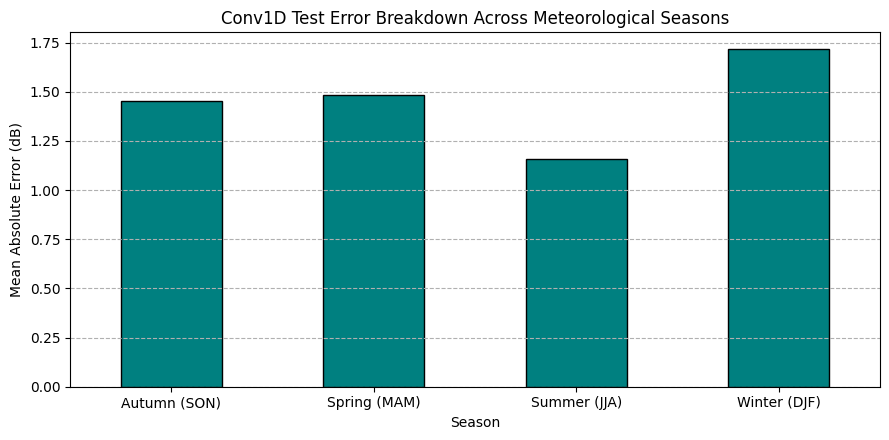

In [18]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from sklearn.metrics import mean_absolute_error

print("\n--- RUNNING SEASONAL ERROR ANALYSIS ---")

# 1. Re-extract or align dates for the test set
all_dates_list = []
for p_id in df_sar['point_id'].unique():
    p_subset = df_sar[df_sar['point_id'] == p_id].sort_values('date')
    p_data_len = len(p_subset) - SEQ_LENGTH
    if p_data_len > 1:
        p_dates = p_subset['date'].values[SEQ_LENGTH:]
        all_dates_list.extend(p_dates)

all_dates_array = np.array(all_dates_list)
test_dates = all_dates_array[split_idx:]  # Align with your 80/20 test split index

# 2. Define Meteorological Season Mapping Function
def get_season(date):
    month = pd.to_datetime(date).month
    if month in [12, 1, 2]: return 'Winter (DJF)'
    elif month in [3, 4, 5]: return 'Spring (MAM)'
    elif month in [6, 7, 8]: return 'Summer (JJA)'
    else: return 'Autumn (SON)'

seasons = [get_season(d) for d in test_dates]

# Ensure lengths match precisely for DataFrame construction
min_len = min(len(test_dates), len(actual_dB), len(conv_dB), len(seasons))

# 3. Build Error DataFrame
error_df = pd.DataFrame({
    'Date': test_dates[:min_len],
    'Actual': actual_dB[:min_len],
    'Predicted': conv_dB[:min_len],
    'Season': seasons[:min_len]
})
error_df['Absolute_Error'] = np.abs(error_df['Actual'] - error_df['Predicted'])

# 4. Aggregate by Season
seasonal_summary = error_df.groupby('Season')['Absolute_Error'].agg(['mean', 'median', 'count'])
print("\nMean Absolute Error (MAE) by Season:")
print(seasonal_summary)

# 5. Plot Seasonal MAE breakdown
plt.figure(figsize=(9, 4.5))
seasonal_summary['mean'].plot(kind='bar', color='teal', edgecolor='black')
plt.title('Conv1D Test Error Breakdown Across Meteorological Seasons')
plt.ylabel('Mean Absolute Error (dB)')
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--')
plt.tight_layout()
plt.show()

In [22]:
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score
import os

print("\n--- RUNNING STRICT LOGO-CV FOR TRADITIONAL ML BASELINES (OPTIMIZED) ---")

local_csv_path = "turlough_s1_extract.csv"
clusters_csv_path = "locked_turlough_clusters.csv"

if not os.path.exists(local_csv_path) or not os.path.exists(clusters_csv_path):
    raise FileNotFoundError("Required CSV files ('turlough_s1_extract.csv' and 'locked_turlough_clusters.csv') not found.")

df_sar = pd.read_csv(local_csv_path)
df_sar['date'] = pd.to_datetime(df_sar['date'])
df_sar = df_sar.sort_values(['point_id', 'date']).dropna(subset=['VV', 'VH'])

df_clusters = pd.read_csv(clusters_csv_path)
basin_to_cluster = dict(zip(df_clusters['point_id'], df_clusters['cluster_id']))

def build_logo_tabular_dataset(df, feature_cols, seq_length=12, target_horizon=1):
    scaler = StandardScaler()
    scaled_data = scaler.fit_transform(df[feature_cols].values)

    df_temp = df.copy()
    for idx, col in enumerate(feature_cols):
        df_temp[f'scaled_{col}'] = scaled_data[:, idx]

    X_list, y_list, groups_list, original_y_list = [], [], [], []

    for p_id in df['point_id'].unique():
        if p_id not in basin_to_cluster:
            continue
        c_id = basin_to_cluster[p_id]
        p_subset = df_temp[df_temp['point_id'] == p_id]

        if len(p_subset) > seq_length + target_horizon:
            p_mat = p_subset[[f'scaled_{c}' for c in feature_cols]].values
            p_raw_target = p_subset['VV'].values

            for i in range(len(p_mat) - seq_length - target_horizon + 1):
                # Flatten sequence window for traditional tabular models
                seq_window = p_mat[i : i + seq_length].flatten()
                target_val = p_mat[i + seq_length + target_horizon - 1, 0]
                raw_val = p_raw_target[i + seq_length + target_horizon - 1]

                X_list.append(seq_window)
                y_list.append(target_val)
                original_y_list.append(raw_val)
                groups_list.append(c_id)

    return np.array(X_list), np.array(y_list), np.array(groups_list), np.array(original_y_list), scaler

feature_cols = ['VV', 'VH']
SEQ_LENGTH = 12
X_all, y_all, groups_all, orig_y_all, scaler = build_logo_tabular_dataset(df_sar, feature_cols, seq_length=SEQ_LENGTH)

logo = LeaveOneGroupOut()

# Optimized hyperparameters to prevent long run times while maintaining benchmark quality
models_to_evaluate = {
    'Random Forest (LOGO)': RandomForestRegressor(n_estimators=30, max_depth=10, random_state=42, n_jobs=-1),
    'XGBoost (LOGO)': XGBRegressor(n_estimators=50, learning_rate=0.05, max_depth=5, random_state=42, n_jobs=-1)
}

logo_ml_results = {}
unique_groups = np.unique(groups_all)

for model_name, model in models_to_evaluate.items():
    print(f"\nEvaluating [{model_name}] under strict Leave-One-Group-Out CV...")
    fold_preds, fold_actuals = [], []
    model_fold_rmses = []

    for fold_idx, (train_idx, test_idx) in enumerate(logo.split(X_all, y_all, groups=groups_all)):
        current_cluster = unique_groups[fold_idx] if fold_idx < len(unique_groups) else "Unknown"
        print(f" -> Processing fold {fold_idx + 1} / {len(unique_groups)} (Cluster ID: {current_cluster})...")

        X_tr, X_te = X_all[train_idx], X_all[test_idx]
        y_tr, y_te = y_all[train_idx], y_all[test_idx]

        if len(X_te) == 0:
            continue

        # Fit model on training clusters
        model.fit(X_tr, y_tr)
        preds_sc = model.predict(X_te)

        # Inverse transform back to original dB scale
        dp = np.zeros((len(preds_sc), len(feature_cols)))
        dp[:, 0] = preds_sc
        preds_db = scaler.inverse_transform(dp)[:, 0]

        orig_y_te = orig_y_all[test_idx]

        # Calculate fold-specific RMSE
        fold_rmse = np.sqrt(mean_squared_error(orig_y_te, preds_db))
        model_fold_rmses.append(fold_rmse)

        fold_preds.extend(preds_db)
        fold_actuals.extend(orig_y_te)

    fold_preds = np.array(fold_preds)
    fold_actuals = np.array(fold_actuals)

    overall_rmse = np.sqrt(mean_squared_error(fold_actuals, fold_preds))
    overall_r2 = r2_score(fold_actuals, fold_preds)

    logo_ml_results[model_name] = {'RMSE': overall_rmse, 'R2': overall_r2, 'Fold_RMSEs': model_fold_rmses}
    print(f" -> Overall LOGO-CV [{model_name}] -> RMSE: {overall_rmse:.2f} dB | R²: {overall_r2:.3f}")

print("\n" + "="*50)
print("TRADITIONAL ML LOGO-CV SUMMARY")
print("="*50)
for k, v in logo_ml_results.items():
    print(f"{k:22} -> Overall RMSE: {v['RMSE']:.2f} dB | R²: {v['R2']:.3f}")
print("="*50)


--- RUNNING STRICT LOGO-CV FOR TRADITIONAL ML BASELINES (OPTIMIZED) ---

Evaluating [Random Forest (LOGO)] under strict Leave-One-Group-Out CV...
 -> Processing fold 1 / 7 (Cluster ID: 0)...
 -> Processing fold 2 / 7 (Cluster ID: 1)...
 -> Processing fold 3 / 7 (Cluster ID: 2)...
 -> Processing fold 4 / 7 (Cluster ID: 3)...
 -> Processing fold 5 / 7 (Cluster ID: 4)...
 -> Processing fold 6 / 7 (Cluster ID: 5)...
 -> Processing fold 7 / 7 (Cluster ID: 6)...
 -> Overall LOGO-CV [Random Forest (LOGO)] -> RMSE: 1.96 dB | R²: 0.749

Evaluating [XGBoost (LOGO)] under strict Leave-One-Group-Out CV...
 -> Processing fold 1 / 7 (Cluster ID: 0)...
 -> Processing fold 2 / 7 (Cluster ID: 1)...
 -> Processing fold 3 / 7 (Cluster ID: 2)...
 -> Processing fold 4 / 7 (Cluster ID: 3)...
 -> Processing fold 5 / 7 (Cluster ID: 4)...
 -> Processing fold 6 / 7 (Cluster ID: 5)...
 -> Processing fold 7 / 7 (Cluster ID: 6)...
 -> Overall LOGO-CV [XGBoost (LOGO)] -> RMSE: 2.00 dB | R²: 0.740

TRADITIONAL ML L

In [25]:
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, r2_score
import os

print("\n--- RUNNING TRADITIONAL ML BASELINES (Random Forest & XGBoost) ---")

local_csv_path = "turlough_s1_extract.csv"
if not os.path.exists(local_csv_path):
    raise FileNotFoundError(f"Dataset '{local_csv_path}' not found.")

df_sar = pd.read_csv(local_csv_path)
df_sar['date'] = pd.to_datetime(df_sar['date'])
df_sar = df_sar.sort_values(['point_id', 'date']).dropna(subset=['VV', 'VH'])

def create_tabular_sequences(df, feature_cols, seq_length=12, target_horizon=1):
    from sklearn.preprocessing import StandardScaler
    scaler = StandardScaler()
    scaled_data = scaler.fit_transform(df[feature_cols].values)

    X_flat, y_list, orig_y_list = [], [], []
    for p_id in df['point_id'].unique():
        p_subset = df[df['point_id'] == p_id]
        if len(p_subset) > seq_length + target_horizon:
            p_mat = scaled_data[(df['point_id'] == p_id).values]
            p_raw = p_subset['VV'].values

            for i in range(len(p_mat) - seq_length - target_horizon + 1):
                seq_window = p_mat[i : i + seq_length].flatten()
                target_val = p_mat[i + seq_length + target_horizon - 1, 0]
                orig_target = p_raw[i + seq_length + target_horizon - 1]

                X_flat.append(seq_window)
                y_list.append(target_val)
                orig_y_list.append(orig_target)

    return np.array(X_flat), np.array(y_list), np.array(orig_y_list), scaler

feature_cols = ['VV', 'VH']
SEQ_LENGTH = 12
X_tab, y_tab, orig_y_tab, scaler_tab = create_tabular_sequences(df_sar, feature_cols, seq_length=SEQ_LENGTH)

split_idx = int(len(X_tab) * 0.8)
X_train_ml, X_test_ml = X_tab[:split_idx], X_tab[split_idx:]
y_train_ml, y_test_ml = y_tab[:split_idx], y_tab[split_idx:]
orig_y_test = orig_y_tab[split_idx:]

ml_results = {}

# 1. Random Forest Regressor (Fixed trailing comma)
print("\nTraining Random Forest Regressor...")
rf_model = RandomForestRegressor(n_estimators=30, max_depth=10, random_state=42, n_jobs=-1)
rf_model.fit(X_train_ml, y_train_ml)
rf_preds_sc = rf_model.predict(X_test_ml)

dp_rf = np.zeros((len(rf_preds_sc), len(feature_cols)))
dp_rf[:, 0] = rf_preds_sc
rf_preds_db = scaler_tab.inverse_transform(dp_rf)[:, 0]

rf_rmse = np.sqrt(mean_squared_error(orig_y_test, rf_preds_db))
rf_r2 = r2_score(orig_y_test, rf_preds_db)
ml_results['Random Forest'] = {'RMSE': rf_rmse, 'R2': rf_r2}
print(f"[Random Forest] RMSE: {rf_rmse:.2f} dB | R²: {rf_r2:.3f}")

# 2. XGBoost Regressor
print("\nTraining XGBoost Regressor...")
xgb_model = XGBRegressor(n_estimators=50, learning_rate=0.05, max_depth=5, random_state=42, n_jobs=-1)
xgb_model.fit(X_train_ml, y_train_ml)
xgb_preds_sc = xgb_model.predict(X_test_ml)

dp_xgb = np.zeros((len(xgb_preds_sc), len(feature_cols)))
dp_xgb[:, 0] = xgb_preds_sc
xgb_preds_db = scaler_tab.inverse_transform(dp_xgb)[:, 0]

xgb_rmse = np.sqrt(mean_squared_error(orig_y_test, xgb_preds_db))
xgb_r2 = r2_score(orig_y_test, xgb_preds_db)
ml_results['XGBoost'] = {'RMSE': xgb_rmse, 'R2': xgb_r2}
print(f"[XGBoost] RMSE: {xgb_rmse:.2f} dB | R²: {xgb_r2:.3f}")

print("\n" + "="*50)
print("TRADITIONAL ML BASELINES SUMMARY")
print("="*50)
for k, v in ml_results.items():
    print(f"{k:18} -> RMSE: {v['RMSE']:.2f} dB | R²: {v['R2']:.3f}")
print("="*50)


--- RUNNING TRADITIONAL ML BASELINES (Random Forest & XGBoost) ---

Training Random Forest Regressor...
[Random Forest] RMSE: 2.02 dB | R²: 0.769

Training XGBoost Regressor...
[XGBoost] RMSE: 2.06 dB | R²: 0.758

TRADITIONAL ML BASELINES SUMMARY
Random Forest      -> RMSE: 2.02 dB | R²: 0.769
XGBoost            -> RMSE: 2.06 dB | R²: 0.758


In [26]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.metrics import mean_squared_error, r2_score
import os

print("\n--- RUNNING STRICT LOGO-CV FOR COMPARATIVE BENCHMARK & ABLATION ---")

local_csv_path = "turlough_s1_extract.csv"
clusters_csv_path = "locked_turlough_clusters.csv"

if not os.path.exists(local_csv_path) or not os.path.exists(clusters_csv_path):
    raise FileNotFoundError("Required CSV files ('turlough_s1_extract.csv' and 'locked_turlough_clusters.csv') not found.")

df_sar = pd.read_csv(local_csv_path)
df_sar['date'] = pd.to_datetime(df_sar['date'])
df_sar = df_sar.sort_values(['point_id', 'date']).dropna(subset=['VV', 'VH'])

df_clusters = pd.read_csv(clusters_csv_path)
basin_to_cluster = dict(zip(df_clusters['point_id'], df_clusters['cluster_id']))

class SARDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32).unsqueeze(1)
    def __len__(self):
        return len(self.X)
    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

class Conv1DAbationPredictor(nn.Module):
    def __init__(self, input_channels, seq_length=12):
        super(Conv1DAbationPredictor, self).__init__()
        self.conv1 = nn.Sequential(
            nn.Conv1d(input_channels, 32, kernel_size=3, padding=1),
            nn.BatchNorm1d(32), nn.ReLU(), nn.MaxPool1d(2)
        )
        self.conv2 = nn.Sequential(
            nn.Conv1d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm1d(64), nn.ReLU()
        )
        self.fc = nn.Sequential(
            nn.Linear(64 * (seq_length // 2), 64),
            nn.ReLU(), nn.Dropout(0.2), nn.Linear(64, 1)
        )
    def forward(self, x):
        x = self.conv1(x.transpose(1, 2))
        x = self.conv2(x)
        return self.fc(x.view(x.size(0), -1))

class LSTMFloodPredictor(nn.Module):
    def __init__(self, input_dim=2, hidden_dim=64):
        super(LSTMFloodPredictor, self).__init__()
        self.lstm = nn.LSTM(input_dim, hidden_dim, batch_first=True)
        self.fc = nn.Sequential(nn.Linear(hidden_dim, 32), nn.ReLU(), nn.Linear(32, 1))
    def forward(self, x):
        out, _ = self.lstm(x)
        return self.fc(out[:, -1, :])

def build_logo_dataset(df, feature_cols, seq_length=12, target_horizon=1):
    scaler = StandardScaler()
    scaled_data = scaler.fit_transform(df[feature_cols].values)

    # Temporarily append scaled values to DataFrame for easy slicing per point
    df_temp = df.copy()
    for idx, col in enumerate(feature_cols):
        df_temp[f'scaled_{col}'] = scaled_data[:, idx]

    X_list, y_list, groups_list, original_y_list = [], [], [], []

    for p_id in df['point_id'].unique():
        if p_id not in basin_to_cluster:
            continue
        c_id = basin_to_cluster[p_id]
        p_subset = df_temp[df_temp['point_id'] == p_id]

        if len(p_subset) > seq_length + target_horizon:
            p_mat = p_subset[[f'scaled_{c}' for c in feature_cols]].values
            p_raw_target = p_subset['VV'].values # For inverse tracking / reporting

            for i in range(len(p_mat) - seq_length - target_horizon + 1):
                X_list.append(p_mat[i : i + seq_length])
                y_list.append(p_mat[i + seq_length + target_horizon - 1, 0])
                original_y_list.append(p_raw_target[i + seq_length + target_horizon - 1])
                groups_list.append(c_id)

    return np.array(X_list), np.array(y_list), np.array(groups_list), np.array(original_y_list), scaler

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
SEQ_LENGTH = 12
logo = LeaveOneGroupOut()

# Configurations to run through strict LOGO-CV
configurations = [
    ('Conv1D (Both VV+VH)', ['VV', 'VH'], 'conv'),
    ('LSTM (Both VV+VH)', ['VV', 'VH'], 'lstm'),
    ('Conv1D (VH-only)', ['VH'], 'conv'),
    ('Conv1D (VV-only)', ['VV'], 'conv')
]

logo_results = {}

for name, cols, model_type in configurations:
    print(f"\nEvaluating [{name}] under strict Leave-One-Group-Out CV...")
    X_all, y_all, groups_all, orig_y_all, scaler = build_logo_dataset(df_sar, cols, seq_length=SEQ_LENGTH)

    fold_preds, fold_actuals = [], []

    for train_idx, test_idx in logo.split(X_all, y_all, groups=groups_all):
        X_tr, X_te = X_all[train_idx], X_all[test_idx]
        y_tr, y_te = y_all[train_idx], y_all[test_idx]

        if len(X_te) == 0:
            continue

        train_loader = DataLoader(SARDataset(X_tr, y_tr), batch_size=128, shuffle=True)
        test_loader = DataLoader(SARDataset(X_te, y_te), batch_size=128, shuffle=False)

        if model_type == 'conv':
            model = Conv1DAbationPredictor(input_channels=len(cols), seq_length=SEQ_LENGTH).to(device)
        else:
            model = LSTMFloodPredictor(input_dim=len(cols), hidden_dim=64).to(device)

        optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
        criterion = nn.MSELoss()

        model.train()
        for epoch in range(8): # Quick training per fold
            for X_b, y_b in train_loader:
                optimizer.zero_grad()
                criterion(model(X_b.to(device)), y_b.to(device)).backward()
                optimizer.step()

        model.eval()
        with torch.no_grad():
            for X_b, y_b in test_loader:
                preds_sc = model(X_b.to(device)).cpu().numpy().flatten()

                # Inverse transform back to original dB scale
                dp = np.zeros((len(preds_sc), len(cols)))
                dp[:, 0] = preds_sc
                preds_db = scaler.inverse_transform(dp)[:, 0]

                fold_preds.extend(preds_db)

        # Align actual raw values for this fold test subset
        orig_y_te = orig_y_all[test_idx]
        fold_actuals.extend(orig_y_te)

    fold_preds = np.array(fold_preds)
    fold_actuals = np.array(fold_actuals)

    rmse = np.sqrt(mean_squared_error(fold_actuals, fold_preds))
    r2 = r2_score(fold_actuals, fold_preds)
    logo_results[name] = {'RMSE': rmse, 'R2': r2}
    print(f" -> LOGO-CV Result [{name}] -> RMSE: {rmse:.2f} dB | R²: {r2:.3f}")

print("\n" + "="*50)
print("STRICT LEAVE-ONE-GROUP-OUT (LOGO) SUMMARY")
print("="*50)
for k, v in logo_results.items():
    print(f"{k:25} -> RMSE: {v['RMSE']:.2f} dB | R²: {v['R2']:.3f}")
print("="*50)


--- RUNNING STRICT LOGO-CV FOR COMPARATIVE BENCHMARK & ABLATION ---

Evaluating [Conv1D (Both VV+VH)] under strict Leave-One-Group-Out CV...
 -> LOGO-CV Result [Conv1D (Both VV+VH)] -> RMSE: 1.94 dB | R²: 0.754

Evaluating [LSTM (Both VV+VH)] under strict Leave-One-Group-Out CV...
 -> LOGO-CV Result [LSTM (Both VV+VH)] -> RMSE: 1.95 dB | R²: 0.751

Evaluating [Conv1D (VH-only)] under strict Leave-One-Group-Out CV...
 -> LOGO-CV Result [Conv1D (VH-only)] -> RMSE: 7.63 dB | R²: -2.796

Evaluating [Conv1D (VV-only)] under strict Leave-One-Group-Out CV...
 -> LOGO-CV Result [Conv1D (VV-only)] -> RMSE: 2.00 dB | R²: 0.738

STRICT LEAVE-ONE-GROUP-OUT (LOGO) SUMMARY
Conv1D (Both VV+VH)       -> RMSE: 1.94 dB | R²: 0.754
LSTM (Both VV+VH)         -> RMSE: 1.95 dB | R²: 0.751
Conv1D (VH-only)          -> RMSE: 7.63 dB | R²: -2.796
Conv1D (VV-only)          -> RMSE: 2.00 dB | R²: 0.738
